# 16. PCA and LDA (dimension reduction)
Preprocessing, not a classifier: the labels are still used by the model trained afterwards.

* **PCA** rotates the standardised features onto the directions of largest variance (eigenvectors of the
  covariance matrix) and keeps the first k. It never looks at the label.
* **LDA** finds the direction that best separates the two classes (between-class vs within-class scatter);
  with 2 classes that is 1 component.

Question tested: does feeding a model fewer, compressed inputs beat the 27 raw features?
From-scratch code: `Notebooks/src/ClassificationAlgorithms/Dimensionreduction.py` · charts: `Results/Classification/16_PCA_LDA/`

## 1. Setup and data

In [1]:
# Setup: imports, data and the fixed 60/20/20 train/validation/test split (seed 42)
import os
import sys

sys.path.insert(0, os.path.abspath(os.path.join("..", "src", "Common")))

import numpy as np
import pandas as pd
from project import Outputs, classification_data
from metrics_classification import roc_auc
import plots
from Dimensionreduction import PCA, compare_reductions, feature_selection_by_importance
from model_zoo import classification_models

out = Outputs("Classification", "16_PCA_LDA")
d = classification_data()
print(
    f"train {d.X_tr.shape} | validation {d.X_va.shape} | test {d.X_te.shape} | "
    f"{len(d.feature_cols)} features | {d.y.mean():.1%} defaulters"
)

train (5746, 27) | validation (1916, 27) | test (1916, 27) | 27 features | 16.0% defaulters


## 2. Model

In [2]:
# PCA on the standardised train features: how many components keep 80 / 90 / 95% of the variance?
pca = PCA(scale=True).fit(d.X_tr, feature_names=d.feature_cols)
ratio = pca.explained_variance_ratio_
cum = np.cumsum(ratio)
variance = pd.DataFrame(
    [
        {
            "variance_target": t,
            "n_components": int(np.searchsorted(cum, t) + 1),
            "total_features": len(d.feature_cols),
            "pc1_share": ratio[0],
            "pc2_share": ratio[1],
        }
        for t in (0.8, 0.9, 0.95)
    ]
)

# Random Forest and linear SVC (settings of notebooks 03 and 06) on raw / PCA / LDA inputs
zoo = classification_models()
rows = []
for name in ("Random Forest", "SVC (linear)"):
    print(name)
    scores = compare_reductions(d.X_tr, d.y_tr, d.X_te, d.y_te, zoo[name][0], roc_auc, n_components=(2, 5, 10, 15))
    for key, auc in scores.items():
        label = "raw features" if key == "raw" else ("LDA" if key == "lda" else f"PCA {key[3:]}")
        n = len(d.feature_cols) if key == "raw" else (1 if key == "lda" else int(key[3:]))
        rows.append({"model": name, "input": label, "n_features": n, "test_roc_auc": auc})
reductions = pd.DataFrame(rows)

# backward feature selection with the Random Forest: drop the least important feature while the
# validation ROC-AUC does not fall by more than 0.01
sel = feature_selection_by_importance(
    zoo["Random Forest"][0], d.feature_cols, d.X_tr, d.y_tr, d.X_va, d.y_va, metric=roc_auc, min_keep=5, tol=0.01
)

Random Forest


  raw features          27 features | test ROC-AUC 0.6884


  PCA 2 comp             2 features | test ROC-AUC 0.6610 | keeps 31.1% of the variance


  PCA 5 comp             5 features | test ROC-AUC 0.6860 | keeps 53.7% of the variance


  PCA 10 comp           10 features | test ROC-AUC 0.6976 | keeps 74.5% of the variance


...

  PCA 2 comp             2 features | test ROC-AUC 0.6803 | keeps 31.1% of the variance


  PCA 5 comp             5 features | test ROC-AUC 0.6882 | keeps 53.7% of the variance


  PCA 10 comp           10 features | test ROC-AUC 0.6963 | keeps 74.5% of the variance


  PCA 15 comp           15 features | test ROC-AUC 0.7002 | keeps 90.9% of the variance


  LDA                    1 features | test ROC-AUC 0.7006


## 3. Results

 variance_target  n_components  total_features  pc1_share  pc2_share
            0.80            12              27   0.192334   0.118899
            0.90            15              27   0.192334   0.118899
            0.95            18              27   0.192334   0.118899

model         Random Forest  SVC (linear)
input                                    
LDA                  0.6870        0.7006
PCA 10               0.6976        0.6963
PCA 15               0.6930        0.7002
PCA 2                0.6610        0.6803
PCA 5                0.6860        0.6882
raw features         0.6884        0.7006


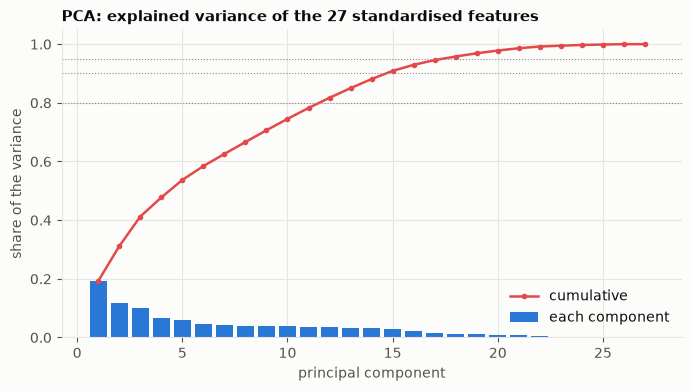

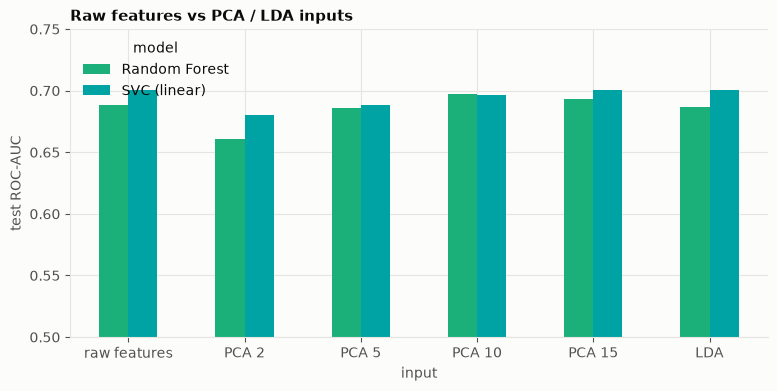

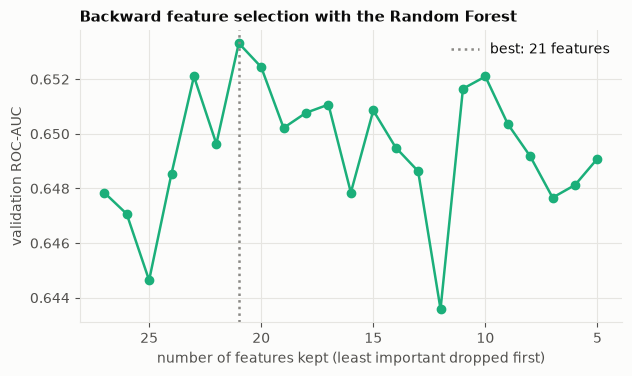


feature selection kept 21 of 27 features (best validation ROC-AUC 0.6533)
left out: pub.rec, policy_fico_mismatch, purpose_credit_card, purpose_educational, purpose_home_improvement, purpose_major_purchase


In [3]:
# Results: explained variance, ROC-AUC with each input, selected features
variance.to_csv(out.table("pca_variance.csv"), index=False)
reductions.to_csv(out.table("dim_reduction.csv"), index=False)
print(variance.to_string(index=False))
print("\n" + reductions.pivot(index="input", columns="model", values="test_roc_auc").round(4).to_string())

fig, ax = plots.plt.subplots(figsize=(8, 4))
ax.bar(np.arange(1, len(ratio) + 1), ratio, color=plots.BLUE, label="each component")
ax.plot(np.arange(1, len(ratio) + 1), cum, "o-", color=plots.RED, markersize=3, label="cumulative")
for t in (0.8, 0.9, 0.95):
    ax.axhline(t, color=plots.NEUTRAL, linestyle=":", linewidth=0.8)
ax.set_xlabel("principal component")
ax.set_ylabel("share of the variance")
ax.set_title("PCA: explained variance of the 27 standardised features")
ax.legend()
plots._save(fig, out.image("pca_explained_variance.png"))

fig, ax = plots.plt.subplots(figsize=(9, 4))
piv = reductions.pivot(index="input", columns="model", values="test_roc_auc")
piv = piv.loc[["raw features", "PCA 2", "PCA 5", "PCA 10", "PCA 15", "LDA"]]
piv.plot.bar(ax=ax, color=["#1baf7a", "#00a3a3"], rot=0)
ax.set_ylim(0.5, max(0.75, piv.max().max() + 0.02))
ax.set_ylabel("test ROC-AUC")
ax.set_title("Raw features vs PCA / LDA inputs")
plots._save(fig, out.image("dim_reduction_roc_auc.png"))

fs = pd.DataFrame(sel["scores"], columns=["n_features", "val_roc_auc"])
fig, ax = plots.plt.subplots(figsize=(7, 3.8))
ax.plot(fs["n_features"], fs["val_roc_auc"], "o-", color="#1baf7a")
ax.axvline(len(sel["keep"]), color=plots.NEUTRAL, linestyle=":", label=f"best: {len(sel['keep'])} features")
ax.invert_xaxis()
ax.set_xlabel("number of features kept (least important dropped first)")
ax.set_ylabel("validation ROC-AUC")
ax.set_title("Backward feature selection with the Random Forest")
ax.legend()
plots._save(fig, out.image("feature_selection.png"))
fs.to_csv(out.table("feature_selection.csv"), index=False)
print(
    f"\nfeature selection kept {len(sel['keep'])} of {len(d.feature_cols)} features (best validation ROC-AUC {sel['best_score']:.4f})"
)
print("left out:", ", ".join(f for f in d.feature_cols if f not in sel["keep"]) or "none")